In [ ]:
import os
from collections import Counter, defaultdict
import numpy as np

run_times = 100

anne_iterations = 2500
anne_init_temp = 100

gene_population_size = 150
gene_mutation_rate = 0.15
gene_crossover_rate = 0.7
gene_iterations = 500

n_to_test = range(4, 13)

In [2]:
def save_const_stats(stats, output, n):
    file = os.path.join(output, f"constraint_stats_size_{n}.txt")
    with open(file, 'w') as f:
        f.write("Constraint Backtracking Solver Statistics\n")
        f.write(f"Table Size: {n}\n")
        # estrai le soluzioni (escludendo entry con lista vuota)
        solutions = [tuple(s[0]) for s in stats if s[0]]

        # conteggi e unici
        counts = Counter(solutions)
        unique_solutions = list(counts.keys())

        # iterations arrays
        all_iterations = np.array([s[1] for s in stats])
        backtracking_counts = np.array([s[2] for s in stats]) 

        # iterations per unique solution
        iters_per_solution = defaultdict(list)
        backtracking_per_solution = defaultdict(list)
        for sol, it, back, solflag in stats:
            if sol:  # only consider non-empty solution arrays as keys
                iters_per_solution[tuple(sol)].append(it)
                backtracking_per_solution[tuple(sol)].append(back)

        f.write(f"Total runs: {len(stats)}\n")

        # overall iterations stats (all runs)
        f.write("\nOverall iterations (all runs):\n")
        f.write(f"  min: {int(all_iterations.min())}\n")
        f.write(f"  max: {int(all_iterations.max())}\n")
        f.write(f"  mean: {float(all_iterations.mean())}\n")
        f.write(f"  median: {float(np.median(all_iterations))}\n")
        f.write(f"  std: {float(all_iterations.std())}\n")

        f.write("\nBacktracking counts (all runs):\n")
        f.write(f"  min: {int(backtracking_counts.min())}\n")
        f.write(f"  max: {int(backtracking_counts.max())}\n")
        f.write(f"  mean: {float(backtracking_counts.mean())}\n")
        f.write(f"  median: {float(np.median(backtracking_counts))}\n")
        f.write(f"  std: {float(backtracking_counts.std())}\n")

        f.write(f"\nUnique solutions count: {len(unique_solutions)}\n")
        f.write("Frequencies and iteration stats per unique solution:\n")
        for sol in unique_solutions:
            iters = np.array(iters_per_solution[sol])
            backtracks = np.array(backtracking_per_solution[sol])
            f.write(f"  Solution: {list(sol)}, count: {counts[sol]}\n")
            if iters.size:
                f.write(f"    iters -> min: {int(iters.min())}, mean: {float(iters.mean()):.2f}, max: {int(iters.max())}, median: {float(np.median(iters)):.2f}, std: {float(iters.std()):.2f}\n")
            else:
                f.write("    no iteration data\n")
            
            if backtracks.size:
                f.write(f"    backtracks -> min: {int(backtracks.min())}, mean: {float(backtracks.mean()):.2f}, max: {int(backtracks.max())}, median: {float(np.median(backtracks)):.2f}, std: {float(backtracks.std()):.2f}\n")
            else:
                f.write("    no backtracking data\n")

In [ ]:
from simulated_annealing_solve import AnnealingExperiment
import matplotlib.pyplot as plt
import numpy as np

def run_experiments(schedule_type, initial_temperature, max_iterations, table_size, cooling_rate,output_dir, n_runs=run_times):
    solutions_found = 0
    final_scores = []
    iterations_to_solution = []
    
    executed = False
    for i in range(n_runs):
        exp = AnnealingExperiment(
            initial_temperature=initial_temperature,
            max_iterations=max_iterations,
            table_size=table_size,
            schedule_type=schedule_type,
            cooling_rate=cooling_rate
        )
        result, score = exp.simulated_annealing(exp.current_state)
        
        final_scores.append(score)
        if score == 0:
            solutions_found += 1
            
            if not executed:
                print(f"\nFirst solution found in run {i+1} with iteration {len(exp.history)}:")
                save_path_hist = os.path.join(output_dir, f"annealing_{schedule_type}_iter_{len(exp.history)}_history_sol_size_{table_size}.png")
                save_path_comp = os.path.join(output_dir, f"annealing_{schedule_type}_iter_{len(exp.history)}_comprehensive_sol_size_{table_size}.png")
                exp.visualize_history(save_path=save_path_hist)
                exp.visualize_comprehensive(save_path=save_path_comp)
                pass

            executed = True

            # Find iteration where solution was found
            for idx, (_, fitness, _) in enumerate(exp.history):
                if fitness == 0:
                    iterations_to_solution.append(idx)
                    break
    
    success_rate = (solutions_found / n_runs) * 100
    avg_final_score = np.mean(final_scores)
    median_final_score = np.median(final_scores)
    avg_iterations = np.mean(iterations_to_solution) if iterations_to_solution else None
    
    return {
        'schedule_type': schedule_type,
        'success_rate': success_rate,
        'solutions_found': solutions_found,
        'total_runs': n_runs,
        'final_scores': final_scores,
        'avg_final_score': avg_final_score,
        'median_final_score': median_final_score,
        'iterations_to_solution': iterations_to_solution,
        'avg_iterations': avg_iterations
    }

def save_annealing_stats(stats_list, output, n):
    file = os.path.join(output, f"annealing_stats_size_{n}.txt")
    with open(file, 'w') as f:
        f.write("Simulated Annealing Solver Statistics\n")
        for stats in stats_list:
            f.write(f"\nSchedule Type: {stats['schedule_type']}\n")
            f.write(f"Total Runs: {stats['total_runs']}\n")
            f.write(f"Solutions Found: {stats['solutions_found']}\n")
            f.write(f"Success Rate: {stats['success_rate']:.2f}%\n")
            f.write(f"Average Final Score: {stats['avg_final_score']:.2f}\n")
            f.write(f"Median Final Score: {stats['median_final_score']:.2f}\n")
            if stats['avg_iterations'] is not None:
                f.write(f"Average Iterations to Solution: {stats['avg_iterations']:.2f}\n")
            else:
                f.write("No solutions found, so no iterations to solution data.\n")
    
    results_linear = stats_list[0]
    results_exponential = stats_list[1]
    results_logarithmic = stats_list[2]

    # Visualize comparison
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Success Rate Comparison
    ax1 = axes[0, 0]
    schedules = ['Linear', 'Exponential', 'Logarithmic']
    success_rates = [results_linear['success_rate'], results_exponential['success_rate'], results_logarithmic['success_rate']]
    colors = ['#3498db', '#e74c3c', '#2ecc71']
    bars = ax1.bar(schedules, success_rates, color=colors, alpha=0.7, edgecolor='black')
    ax1.set_ylabel('Success Rate (%)', fontsize=12)
    ax1.set_title('Success Rate by Schedule Type', fontsize=14, fontweight='bold')
    ax1.set_ylim(0, 100)
    ax1.grid(True, alpha=0.3, axis='y')
    # Add value labels on bars
    for bar, rate in zip(bars, success_rates):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{rate:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

    # 2. Final Score Distribution
    ax2 = axes[0, 1]
    all_scores = [results_linear['final_scores'], results_exponential['final_scores'], results_logarithmic['final_scores']]
    bp = ax2.boxplot(all_scores, labels=schedules, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax2.set_ylabel('Final Score (Conflicts)', fontsize=12)
    ax2.set_title('Final Score Distribution', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')

    # 3. Average Final Scores
    ax3 = axes[1, 0]
    avg_scores = [results_linear['avg_final_score'], results_exponential['avg_final_score'], results_logarithmic['avg_final_score']]
    bars = ax3.bar(schedules, avg_scores, color=colors, alpha=0.7, edgecolor='black')
    ax3.set_ylabel('Average Final Score', fontsize=12)
    ax3.set_title('Average Final Score by Schedule Type', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3, axis='y')
    # Add value labels
    for bar, score in zip(bars, avg_scores):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{score:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

    # 4. Iterations to Solution (for successful runs)
    ax4 = axes[1, 1]
    all_iterations = [results_linear['iterations_to_solution'], 
                    results_exponential['iterations_to_solution'],
                    results_logarithmic['iterations_to_solution']]
    # Filter out empty lists
    valid_iterations = [iters for iters in all_iterations if len(iters) > 0]
    valid_labels = [label for label, iters in zip(schedules, all_iterations) if len(iters) > 0]
    if valid_iterations:
        bp = ax4.boxplot(valid_iterations, labels=valid_labels, patch_artist=True)
        for patch, color in zip(bp['boxes'], colors[:len(valid_iterations)]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax4.set_ylabel('Iterations to Solution', fontsize=12)
        ax4.set_title('Iterations to Find Solution (Successful Runs)', fontsize=14, fontweight='bold')
        ax4.grid(True, alpha=0.3, axis='y')
    else:
        ax4.text(0.5, 0.5, 'No solutions found', ha='center', va='center', fontsize=14)
        ax4.set_title('Iterations to Find Solution', fontsize=14, fontweight='bold')

    plt.tight_layout()
    path = os.path.join(output, f'algorithm_comparison_size_{n}_iter_{anne_iterations}_init_temp_{anne_init_temp}.png')
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
# Analyze and summarize results
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def save_genetic_stats(experiments, output, n):

    total_runs = len(experiments)
    successful_runs = [exp for exp in experiments if exp[1]]  # found == True
    failed_runs = [exp for exp in experiments if not exp[1]]

    success_count = len(successful_runs)
    success_rate = (success_count / total_runs) * 100

    file = os.path.join(output, f"genetic_stats_size_{n}.txt")
    with open(file, 'w') as f:
        # Extract data

        f.write("\nOverall Performance:\n")
        f.write(f"  Total Runs: {total_runs}\n")
        f.write(f"  Successful: {success_count} ({success_rate:.1f}%)\n")
        f.write(f"  Failed: {len(failed_runs)} ({100-success_rate:.1f}%)\n")

        # Successful runs statistics
        if successful_runs:
            successful_iterations = [exp[4] for exp in successful_runs]
            successful_fitness = [exp[3] for exp in successful_runs]
            
            f.write("\nSuccessful Runs Statistics:\n")
            f.write("  Iterations to Solution:\n")
            f.write(f"    Min: {np.min(successful_iterations)}\n")
            f.write(f"    Max: {np.max(successful_iterations)}\n")
            f.write(f"    Mean: {np.mean(successful_iterations):.2f}\n")
            f.write(f"    Median: {np.median(successful_iterations):.0f}\n")
            f.write(f"    Std: {np.std(successful_iterations):.2f}\n")
            
            # Count unique solutions
            successful_solutions = [tuple(exp[2]) for exp in successful_runs]
            unique_solutions = Counter(successful_solutions)
            
            f.write(f"\n  Unique Solutions Found: {len(unique_solutions)}\n")
            f.write("  Most Common Solutions:\n")
            for sol, count in unique_solutions.most_common(5):
                f.write(f"    {list(sol)}: {count} times ({100*count/success_count:.1f}%)\n")

        # Failed runs statistics
        if failed_runs:
            failed_fitness = [exp[3] for exp in failed_runs]
            failed_iterations = [exp[4] for exp in failed_runs]
            
            f.write("\nFailed Runs Statistics:\n")
            f.write("  Final Fitness (Conflicts):\n")
            f.write(f"    Best: {np.min(failed_fitness)}\n")
            f.write(f"    Worst: {np.max(failed_fitness)}\n")
            f.write(f"    Mean: {np.mean(failed_fitness):.2f}\n")
            f.write(f"    Median: {np.median(failed_fitness):.0f}\n")

    # Visualizations
    fig = plt.figure(figsize=(16, 12))

    # 1. Success Rate
    ax1 = plt.subplot(3, 3, 1)
    labels = ['Success', 'Failure']
    sizes = [success_count, len(failed_runs)]
    colors = ['#2ecc71', '#e74c3c']
    wedges, texts, autotexts = ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
                                        startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
    ax1.set_title('Success Rate', fontsize=14, fontweight='bold')

    # 2. Iterations Distribution (Successful)
    ax2 = plt.subplot(3, 3, 2)
    if successful_runs:
        ax2.hist(successful_iterations, bins=20, color='#2ecc71', alpha=0.7, edgecolor='black')
        ax2.axvline(np.mean(successful_iterations), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(successful_iterations):.0f}')
        ax2.set_xlabel('Iterations to Solution', fontsize=11)
        ax2.set_ylabel('Frequency', fontsize=11)
        ax2.set_title('Iterations Distribution (Success)', fontsize=13, fontweight='bold')
        ax2.legend()
        ax2.grid(True, alpha=0.3)

    # 3. Final Fitness Distribution (Failed)
    ax3 = plt.subplot(3, 3, 3)
    if failed_runs:
        failed_fitness_flat = [f if isinstance(f, (int, float)) else f[0] if isinstance(f, (list, np.ndarray)) and len(f) > 0 else f for f in failed_fitness]
        ax3.hist(failed_fitness_flat, bins=20, color='#e74c3c', alpha=0.7, edgecolor='black')
        mean_failed = np.mean(failed_fitness_flat)
        ax3.axvline(mean_failed, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_failed:.1f}')
        ax3.set_xlabel('Final Fitness (Conflicts)', fontsize=11)
        ax3.set_ylabel('Frequency', fontsize=11)
        ax3.set_title('Final Fitness Distribution (Failed)', fontsize=13, fontweight='bold')
        ax3.legend()
        ax3.grid(True, alpha=0.3)

    # 4. Convergence Comparison (Sample of runs)
    ax4 = plt.subplot(3, 3, 4)
    sample_size = min(1000, len(experiments))
    for idx, (exp_obj, found, _, _, _) in enumerate(experiments[:sample_size]):
        color = '#2ecc71' if found else '#e74c3c'
        alpha = 0.8 if found else 0.3
        ax4.plot(exp_obj.history['generation'], exp_obj.history['best_fitness'], 
                linewidth=1.5, alpha=alpha, color=color)
    ax4.set_xlabel('Generation', fontsize=11)
    ax4.set_ylabel('Best Fitness', fontsize=11)
    ax4.set_title(f'Convergence (First {sample_size} Runs)', fontsize=13, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    ax4.axhline(y=0, color='green', linestyle='--', alpha=0.5)

    # 5. Average Fitness Evolution
    ax5 = plt.subplot(3, 3, 5)
    all_best_fitness = [exp[0].history['best_fitness'] for exp in experiments]
    all_avg_fitness = [exp[0].history['avg_fitness'] for exp in experiments]
    # Pad sequences to same length
    max_len = max(len(f) for f in all_best_fitness)
    padded_best = [f + [f[-1]]*(max_len - len(f)) for f in all_best_fitness]
    padded_avg = [f + [f[-1]]*(max_len - len(f)) for f in all_avg_fitness]

    mean_best = np.mean(padded_best, axis=0)
    mean_avg = np.mean(padded_avg, axis=0)
    std_best = np.std(padded_best, axis=0)

    generations = range(max_len)
    ax5.plot(generations, mean_best, linewidth=2, color='blue', label='Mean Best')
    ax5.fill_between(generations, mean_best - std_best, mean_best + std_best, alpha=0.3, color='blue')
    ax5.plot(generations, mean_avg, linewidth=2, color='orange', label='Mean Average', alpha=0.7)
    ax5.set_xlabel('Generation', fontsize=11)
    ax5.set_ylabel('Fitness', fontsize=11)
    ax5.set_title('Average Fitness Evolution', fontsize=13, fontweight='bold')
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    ax5.axhline(y=0, color='green', linestyle='--', alpha=0.5)

    # 6. Diversity Evolution
    ax6 = plt.subplot(3, 3, 6)
    all_diversity = [exp[0].history['diversity'] for exp in experiments]
    padded_diversity = [d + [d[-1]]*(max_len - len(d)) for d in all_diversity]
    mean_diversity = np.mean(padded_diversity, axis=0)
    std_diversity = np.std(padded_diversity, axis=0)

    ax6.plot(generations, mean_diversity, linewidth=2, color='purple')
    ax6.fill_between(generations, mean_diversity - std_diversity, mean_diversity + std_diversity, alpha=0.3, color='purple')
    ax6.set_xlabel('Generation', fontsize=11)
    ax6.set_ylabel('Diversity Ratio', fontsize=11)
    ax6.set_title('Average Population Diversity', fontsize=13, fontweight='bold')
    ax6.grid(True, alpha=0.3)
    ax6.set_ylim([0, 1])

    plt.suptitle(f'Genetic Algorithm Analysis ({total_runs} runs)', fontsize=16, fontweight='bold')
    plt.tight_layout()
    path = os.path.join(output, f'genetic_size_{n}_iter_{gene_iterations}_mutrate_{gene_mutation_rate}_crossrate_{gene_crossover_rate}_popsize_{gene_population_size}.png')
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

    if successful_runs:
        print("\nVisualizing slowest successful run...")
        best_run = max(successful_runs, key=lambda x: x[4])  # slowest solution
        best_run[0].visualize_evolution(save_path=os.path.join(output, f'genetic_slowest_sol_run_size_{n}.png'))


In [ ]:
def iter_back_boxplot(iterations, backtracks, n, output):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    bp1 = ax1.boxplot(iterations, labels=n, patch_artist=True, 
                       showmeans=True, meanline=True)
    
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(n)))
    for patch, color in zip(bp1['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax1.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Iterations', fontsize=12, fontweight='bold')
    ax1.set_title('Constraint Backtracking: Iterations by Table Size', 
                  fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_yscale('log')  # Log scale 
    
    bp2 = ax2.boxplot(backtracks, labels=n, patch_artist=True,
                       showmeans=True, meanline=True)
    
    for patch, color in zip(bp2['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax2.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Backtracks', fontsize=12, fontweight='bold')
    ax2.set_title('Constraint Backtracking: Backtracks by Table Size', 
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_yscale('log')  # Log scale 
    
    plt.suptitle(f'Constraint Backtracking Performance Comparison ({run_times} runs per size)', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Save the plot
    save_path = os.path.join(output, 'combined_constraint_comparison.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved combined boxplot to: {save_path}")
    plt.show()

In [ ]:

def annealin_boxplots(linear, exponential, logarithmic, n, output):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    linear_iterations = [result['iterations_to_solution'] for result in linear]
    exponential_iterations = [result['iterations_to_solution'] for result in exponential]
    logarithmic_iterations = [result['iterations_to_solution'] for result in logarithmic]

    linear_success_rates = [result['success_rate'] for result in linear]
    exponential_success_rates = [result['success_rate'] for result in exponential]
    logarithmic_success_rates = [result['success_rate'] for result in logarithmic]
    
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(n)))
    
    ax1 = axes[0]
    linear_data = [iters for iters in linear_iterations if len(iters) > 0]
    linear_labels_indices = [i for i, iters in enumerate(linear_iterations) if len(iters) > 0]
    linear_labels = [f'{n[i]}\n({linear_success_rates[i]:.1f}%)' 
                     for i in linear_labels_indices]
    
    if linear_data:
        bp1 = ax1.boxplot(linear_data, labels=linear_labels, patch_artist=True,
                          showmeans=True, meanline=True)
        for patch, color in zip(bp1['boxes'], colors[:len(linear_data)]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
    
    ax1.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Iterations to Solution', fontsize=12, fontweight='bold')
    ax1.set_title('Linear Schedule', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    ax2 = axes[1]
    exponential_data = [iters for iters in exponential_iterations if len(iters) > 0]
    exponential_labels_indices = [i for i, iters in enumerate(exponential_iterations) if len(iters) > 0]
    exponential_labels = [f'{n[i]}\n({exponential_success_rates[i]:.1f}%)' 
                          for i in exponential_labels_indices]
    
    if exponential_data:
        bp2 = ax2.boxplot(exponential_data, labels=exponential_labels, patch_artist=True,
                          showmeans=True, meanline=True)
        for patch, color in zip(bp2['boxes'], colors[:len(exponential_data)]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
    
    ax2.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Iterations to Solution', fontsize=12, fontweight='bold')
    ax2.set_title('Exponential Schedule', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    
    ax3 = axes[2]
    logarithmic_data = [iters for iters in logarithmic_iterations if len(iters) > 0]
    logarithmic_labels_indices = [i for i, iters in enumerate(logarithmic_iterations) if len(iters) > 0]
    logarithmic_labels = [f'{n[i]}\n({logarithmic_success_rates[i]:.1f}%)' 
                          for i in logarithmic_labels_indices]
    
    if logarithmic_data:
        bp3 = ax3.boxplot(logarithmic_data, labels=logarithmic_labels, patch_artist=True,
                          showmeans=True, meanline=True)
        for patch, color in zip(bp3['boxes'], colors[:len(logarithmic_data)]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
    
    ax3.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Iterations to Solution', fontsize=12, fontweight='bold')
    ax3.set_title('Logarithmic Schedule', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3, axis='y')
    
    plt.suptitle(f'Simulated Annealing: Iterations to Solution Comparison ({run_times} runs per size)', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    save_path = os.path.join(output, f'annealing_comparison_iter_{anne_iterations}_temp_{anne_init_temp}.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved annealing comparison boxplot to: {save_path}")
    plt.show()
    

In [ ]:
from contraint_backtracking_solve import ConstraintExperiment
def run_constraint_experiments(n, output_dir):
    stats = []
    for i in range(run_times):
        experiment = ConstraintExperiment(n)
        stats.append(experiment.constrain_backtracking_solve())
    
    save_const_stats(stats, output_dir, n)
    iterations = np.array([s[1] for s in stats])
    backtracks = np.array([s[2] for s in stats])
    return iterations, backtracks  


In [ ]:
def run_annealing_experiments(n, output_dir):
    results_linear = run_experiments('linear', anne_init_temp, anne_iterations, n, 1, n_runs=run_times)
    results_exponential = run_experiments('exponential', anne_init_temp, anne_iterations, n, 0.99, n_runs=run_times)
    results_logarithmic = run_experiments('logarithmic', anne_init_temp, anne_iterations, n, 1, n_runs=run_times)

    save_annealing_stats([results_linear, results_exponential, results_logarithmic], output_dir, n)
    return results_linear, results_exponential, results_logarithmic

In [ ]:
from genetic_algorithm_solve import GeneticExperiment
def run_genetic_experiments(n, output_dir):
    experiments = []
    for i in range(run_times):
        exp_genetic = GeneticExperiment(table_size=n, population_size=gene_population_size, mutation_rate=gene_mutation_rate, crossover_rate=gene_crossover_rate, iterations=gene_iterations)
        found , solution , fitness, iteration = exp_genetic.genetic_solve()
        experiments.append((exp_genetic, found, solution, fitness, iteration))
    
    save_genetic_stats(experiments, output_dir, n)
    return experiments


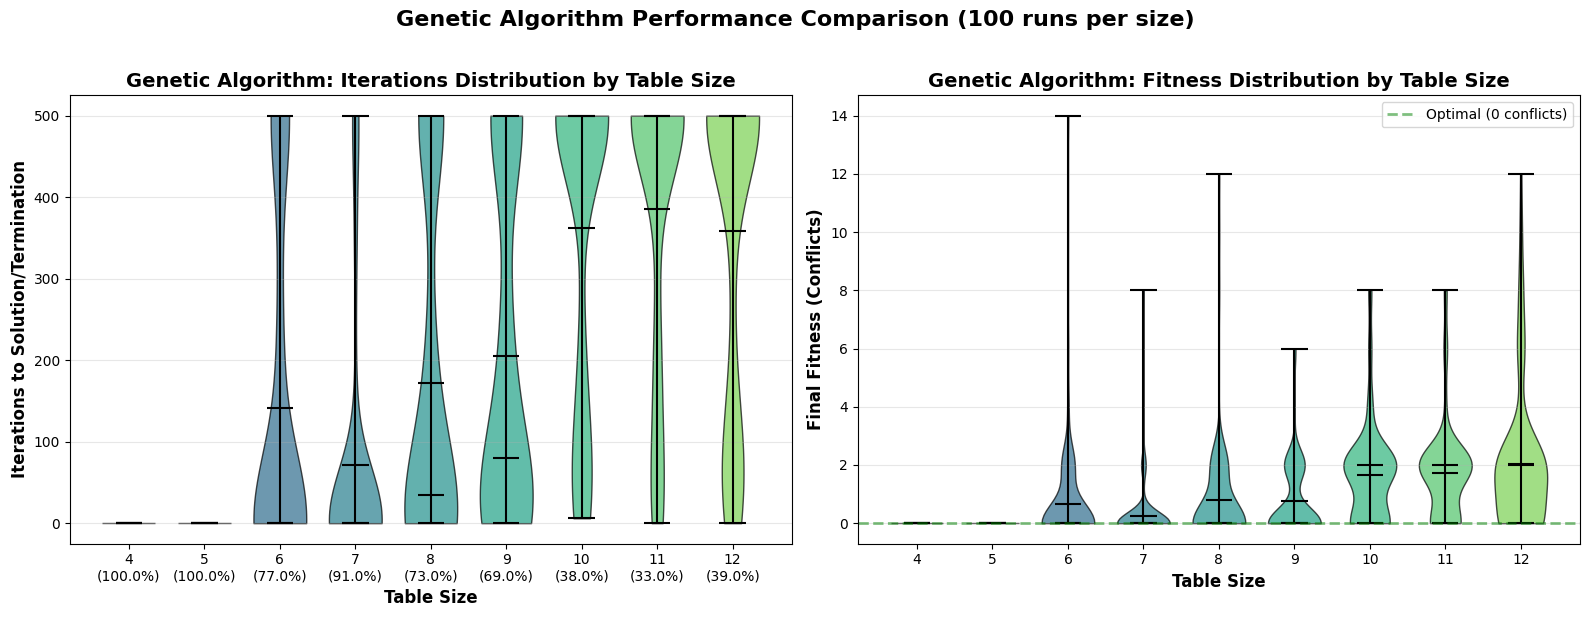

In [ ]:
def genetic_boxplots(all_experiments, n, output):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    iterations_data = []
    fitness_data = []
    success_rates = []
    
    for experiments in all_experiments:
        iters = []
        fits = []
        successful_count = 0

        
        for exp in experiments:
            # exp[4] is iteration, exp[3] is fitness
            iteration_val = exp[4]
            fitness_val = exp[3]
            if exp[1]:  # found == True
                successful_count += 1
            
            # Ensure iteration is a scalar
            # if isinstance(iteration_val, (list, np.ndarray)):
            #     iteration_val = iteration_val[0] if len(iteration_val) > 0 else 0
            iters.append(int(iteration_val))
            
            # Ensure fitness is a scalar
            # if isinstance(fitness_val, (list, np.ndarray)):
            #     fitness_val = fitness_val[0] if len(fitness_val) > 0 else 0 #!!!!
            fits.append(int(fitness_val))
        
        iterations_data.append(iters)
        fitness_data.append(fits)
        success_rate = (successful_count / len(experiments)) * 100
        success_rates.append(success_rate)
    
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(n)))
    
    parts1 = ax1.violinplot(iterations_data, positions=range(len(n)), 
                             showmeans=True, showmedians=True, widths=0.7)
    
    for i, pc in enumerate(parts1['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
    
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cmeans'):
        if partname in parts1:
            parts1[partname].set_edgecolor('black')
            parts1[partname].set_linewidth(1.5)
    
    ax1.set_xticks(range(len(n)))
    labels_with_success = [f'{size}\n({rate:.1f}%)' for size, rate in zip(n, success_rates)]
    ax1.set_xticklabels(labels_with_success)
    ax1.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Iterations to Solution/Termination', fontsize=12, fontweight='bold')
    ax1.set_title('Genetic Algorithm: Iterations Distribution by Table Size', 
                  fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    parts2 = ax2.violinplot(fitness_data, positions=range(len(n)), 
                             showmeans=True, showmedians=True, widths=0.7)
    
    for i, pc in enumerate(parts2['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
    
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cmeans'):
        if partname in parts2:
            parts2[partname].set_edgecolor('black')
            parts2[partname].set_linewidth(1.5)
    
    ax2.set_xticks(range(len(n)))
    ax2.set_xticklabels([str(size) for size in n])
    ax2.set_xlabel('Table Size', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Final Fitness (Conflicts)', fontsize=12, fontweight='bold')
    ax2.set_title('Genetic Algorithm: Fitness Distribution by Table Size', 
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.axhline(y=0, color='green', linestyle='--', alpha=0.5, linewidth=2, label='Optimal (0 conflicts)')
    ax2.legend()
    
    plt.suptitle(f'Genetic Algorithm Performance Comparison ({run_times} runs per size)', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    save_path = os.path.join(output, f'genetic_comparison_iter_{gene_iterations}_mutrate_{gene_mutation_rate}_crossrate_{gene_crossover_rate}_popsize_{gene_population_size}.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved genetic algorithm comparison violin plot to: {save_path}")
    plt.show()


=== Table Size: 4 ===

=== Table Size: 5 ===

=== Table Size: 6 ===

=== Table Size: 7 ===

=== Table Size: 8 ===

=== Table Size: 9 ===

=== Table Size: 10 ===

=== Table Size: 11 ===

=== Table Size: 12 ===


C:\Users\Filippo Gumiero\AppData\Local\Temp\ipykernel_5300\2204346480.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp1 = ax1.boxplot(iterations_data, labels=[str(size) for size in n],


Saved genetic algorithm comparison boxplot to: results/genetic\genetic_comparison_iter_500_mutrate_0.15_crossrate_0.7_popsize_150.png


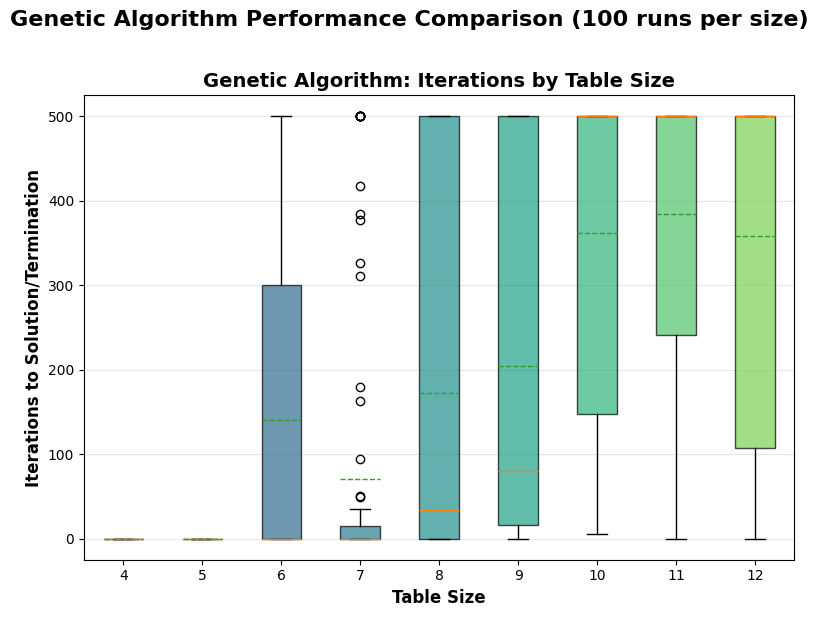

In [ ]:
all_iter = []
all_back = []
for n in n_to_test:
    print(f"\n Table Size: {n}")
    output_dir = f"results/constraint/{n}"
    os.makedirs(output_dir, exist_ok=True)
    iter, back = run_constraint_experiments(n, output_dir)
    all_iter.append(iter)
    all_back.append(back)
iter_back_boxplot(all_iter, all_back, list(n_to_test), "results/constraint")
    
full_linear_results = []
full_exponential_results = []
full_logarithmic_results = []
for n in n_to_test:
    print(f"\nTable Size: {n}")
    output_dir = f"results/annealing/{n}"
    os.makedirs(output_dir, exist_ok=True)
    results_linear, results_exponential, results_logarithmic = run_annealing_experiments(n, output_dir)
    full_linear_results.append(results_linear)
    full_exponential_results.append(results_exponential)
    full_logarithmic_results.append(results_logarithmic)
annealin_boxplots(full_linear_results, full_exponential_results, full_logarithmic_results, list(n_to_test), "results/annealing")

gen_results = []
for n in n_to_test:
    print(f"\nTable Size: {n}")
    output_dir = f"results/genetic/{n}"
    os.makedirs(output_dir, exist_ok=True)
    gen_results.append(run_genetic_experiments(n, output_dir))

genetic_boxplots(gen_results, list(n_to_test), "results/genetic")